# 결정트리와 앙상블

In [ ]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify =y)

print("훈련:", X_train.shape, "/ 테스트:", X_test.shape)

훈련: (455, 30) / 테스트: (114, 30)


In [ ]:
# 지니 불순도 계산
def gini(counts):
  n = sum(counts)
  return 1 - sum((c/n) ** 2 for c in counts)

print("한쪽으로 완전히 몰린 경우[40, 0]:", round(gini([40, 0]), 4))
print("반반인 경우[20, 20]:", round(gini([20, 20]), 4))
print("치우친 경우[30, 10]:", round(gini([30, 10]), 4))

한쪽으로 완전히 몰린 경우[40, 0]: 0.0
반반인 경우[20, 20]: 0.5
치우친 경우[30, 10]: 0.375


In [ ]:
# 분할 전후 비교
before = gini([212, 357])
left, right = [200, 20], [12, 337]

after = (sum(left) * gini(left) + sum(right) * gini(right)) / (sum(left) + sum(right))

print("나누기 전 불순도:", round(before, 4))
print("나눈 뒤 가중평균:", round(after, 4))
print("정보 이득:", round(before - after, 4))

나누기 전 불순도: 0.4675
나눈 뒤 가중평균: 0.1046
정보 이득: 0.3629


In [ ]:
#트리 학습
from sklearn.tree import DecisionTreeClassifier

tree = DecisionTreeClassifier(max_depth=3, random_state=42)
tree.fit(X_train, y_train)

print("훈련 정확도:", round(tree.score(X_train, y_train), 4))
print("테스트 정확도:", round(tree.score(X_test, y_test), 4))

훈련 정확도: 0.9758
테스트 정확도: 0.9386


In [ ]:
#값을 바꿔 다시 학습
from sklearn.preprocessing import StandardScaler

def tree_test_score(A_train, A_test):
  t = DecisionTreeClassifier(max_depth=3, random_state=42).fit(A_train, y_train)
  return round(t.score(A_test, y_test), 4)

sc = StandardScaler()
print("원래 값       :", tree_test_score(X_train, X_test))
print("표준화한 값   :", tree_test_score(sc.fit_transform(X_train),sc.transform(X_test)))
print("100배 곱한 값 :", tree_test_score(X_train * 100, X_test * 100))
print("로그를 씌운 값:", tree_test_score(np.log1p(X_train), np.log1p(X_test)))

원래 값       : 0.9386
표준화한 값   : 0.9386
100배 곱한 값 : 0.9386
로그를 씌운 값: 0.9386


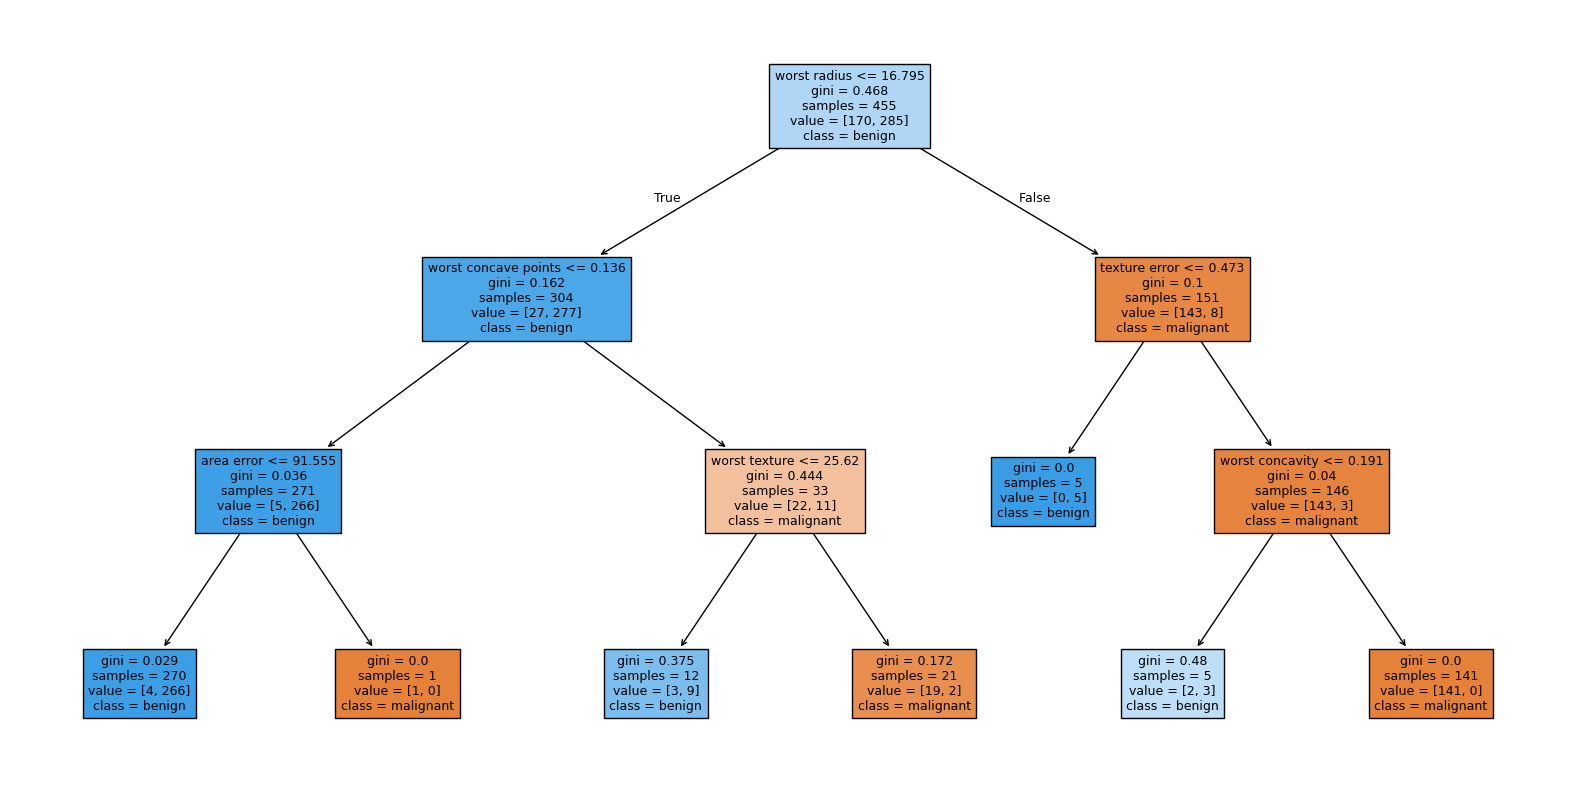

|--- worst radius <= 16.80
|   |--- worst concave points <= 0.14
|   |   |--- area error <= 91.56
|   |   |   |--- class: 1
|   |   |--- area error >  91.56
|   |   |   |--- class: 0
|   |--- worst concave points >  0.14
|   |   |--- worst texture <= 25.62
|   |   |   |--- class: 1
|   |   |--- worst texture >  25.62
|   |   |   |--- class: 0
|--- worst radius >  16.80
|   |--- texture error <= 0.47
|   |   |--- class: 1
|   |--- texture error >  0.47
|   |   |--- worst concavity <= 0.19
|   |   |   |--- class: 1
|   |   |--- worst concavity >  0.19
|   |   |   |--- class: 0



In [ ]:
# 트리 그리기
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree, export_text

plt.figure(figsize=(20,10))
plot_tree(tree, feature_names=data.feature_names,
          class_names=data.target_names, filled=True, fontsize=9)
plt.show()

print(export_text(tree, feature_names=list(data.feature_names))[:600])

## 과적합과 가지치기

In [ ]:
#깊이별로 다시 학습
for d in [1, 2, 3, 5, 10, 20, None]:
  t = DecisionTreeClassifier(max_depth=d, random_state=42)
  t.fit(X_train, y_train)
  print(str(d).rjust(4),
        "|", round(t.score(X_train, y_train), 4),
        "|", round(t.score(X_test, y_test), 4),
        "|", t.get_n_leaves())

   1 | 0.9231 | 0.9211 | 2
   2 | 0.9582 | 0.8947 | 4
   3 | 0.9758 | 0.9386 | 7
   5 | 0.9934 | 0.9211 | 15
  10 | 1.0 | 0.9123 | 19
  20 | 1.0 | 0.9123 | 19
None | 1.0 | 0.9123 | 19


In [ ]:
#잎의 최소 표본 수 조정
for m in [1, 5, 10, 20, 50]:
  t = DecisionTreeClassifier(min_samples_leaf=m, random_state=42)
  t.fit(X_train, y_train)
  print(str(m).rjust(3),
        "|", round(t.score(X_train, y_train), 4),
        "|", round(t.score(X_test, y_test), 4),
        "|", t.get_n_leaves())

  1 | 1.0 | 0.9123 | 19
  5 | 0.9758 | 0.9298 | 13
 10 | 0.9626 | 0.9474 | 10
 20 | 0.9473 | 0.9035 | 7
 50 | 0.9231 | 0.9211 | 5


## 앙상블

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

logi = LogisticRegression(max_iter=1000).fit(X_train_s, y_train)
tree_full = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)
forest = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)

print("로지스틱 회귀 :", round(logi.score(X_test_s, y_test), 4))
print("결정트리 하나 :", round(tree_full.score(X_test, y_test), 4))
print("랜덤포레스트  :", round(forest.score(X_test, y_test), 4))

로지스틱 회귀 : 0.9825
결정트리 하나 : 0.9123
랜덤포레스트  : 0.9561


## 교차검증

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import make_pipeline
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
candidates = [
  ("로지스틱 회귀", make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))),
  ("결정트리 ", DecisionTreeClassifier(random_state=42)),
  ("랜덤포레스트", RandomForestClassifier(n_estimators=100, random_state=42)),
]
for name, model in candidates:
  s = cross_val_score(model, X, y, cv=cv)
  print(name, "| 평균", round(s.mean(), 4), "| 표준편차", round(s.std(), 4))

로지스틱 회귀 | 평균 0.9737 | 표준편차 0.0166
결정트리  | 평균 0.9104 | 표준편차 0.0279
랜덤포레스트 | 평균 0.9561 | 표준편차 0.0123


## 숲의 크기와 다양성

In [ ]:
for n in [1, 5, 10, 50, 100, 300]:
  f = RandomForestClassifier(n_estimators=n, random_state=42)
  f.fit(X_train, y_train)
  print("나무", str(n).rjust(3), "그루 -> 테스트 정확도",
        round(f.score(X_test, y_test), 4))

나무   1 그루 -> 테스트 정확도 0.9474
나무   5 그루 -> 테스트 정확도 0.9386
나무  10 그루 -> 테스트 정확도 0.9386
나무  50 그루 -> 테스트 정확도 0.9561
나무 100 그루 -> 테스트 정확도 0.9561
나무 300 그루 -> 테스트 정확도 0.9474


In [ ]:
# 씨앗 열 개로 다시 측정
for n in [1, 5, 10, 50, 100, 300]:
  scores = np.array([
    RandomForestClassifier(n_estimators=n, random_state=seed)
    .fit(X_train, y_train).score(X_test, y_test)
    for seed in range(10)])
  print("나무", str(n).rjust(3), "그루 -> 평균", round(scores.mean(), 4),
    "| 표준편차", round(scores.std(), 4))


나무   1 그루 -> 평균 0.9246 | 표준편차 0.0153
나무   5 그루 -> 평균 0.9456 | 표준편차 0.0102
나무  10 그루 -> 평균 0.9421 | 표준편차 0.0137
나무  50 그루 -> 평균 0.9544 | 표준편차 0.0053
나무 100 그루 -> 평균 0.9544 | 표준편차 0.0035
나무 300 그루 -> 평균 0.9544 | 표준편차 0.0035
